# Phishing Email Detection with Machine Learning

This notebook builds and evaluates a system that classifies emails as **phishing** or **legitimate**. It follows these steps: data understanding, cleaning, text mining, TF-IDF feature extraction, chi-square feature selection, training and tuning four algorithms, evaluation, and explaining the main model (Logistic Regression).

## 1. Load the dataset
The Kaggle Phishing Email Dataset (Naser Abdullah Alam) combines six public email collections. `text_combined` holds the email text and `label` is 1 for phishing and 0 for legitimate.

In [1]:
import pandas as pd

df = pd.read_csv("archive (1)/phishing_email.csv")

print("Shape:", df.shape)
df.head()

Shape: (82486, 2)


,text_combined,label
0,hpl nom may 25 2001 see attached file hplno 52...,0
1,nom actual vols 24 th forwarded sabrae zajac h...,0
2,enron actuals march 30 april 1 201 estimated a...,0
3,hpl nom may 30 2001 see attached file hplno 53...,0
4,hpl nom june 1 2001 see attached file hplno 60...,0


## 2. Data quality checks
Check for missing values, duplicate rows and empty emails, and see how many emails are in each class.

In [3]:
print("Missing values:")
print(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())

df["word_count"] = df["text_combined"].astype(str).str.split().str.len()
print("Empty emails:", (df["word_count"] == 0).sum())

print("\nClass counts (1 = phishing, 0 = legitimate):")
print(df["label"].value_counts())

Missing values:
text_combined    0
label            0
dtype: int64

Duplicate rows: 408
Empty emails: 1

Class counts (1 = phishing, 0 = legitimate):
label
1    42891
0    39595
Name: count, dtype: int64


## 3. Exploratory data analysis
### 3.1 Class distribution
The two classes are close to balanced, so accuracy is a fair metric and no resampling is needed.

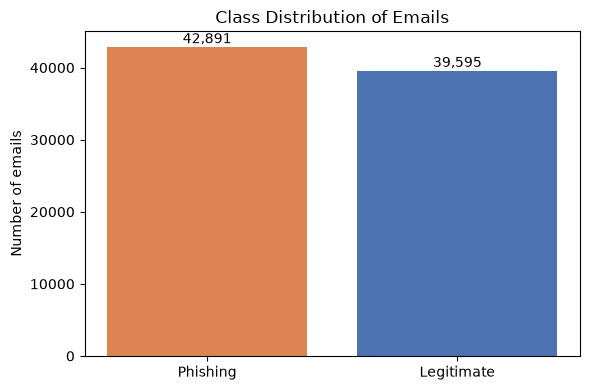

In [4]:
import matplotlib.pyplot as plt
import os

os.makedirs("figures", exist_ok=True)

counts = df["label"].map({0: "Legitimate", 1: "Phishing"}).value_counts()

plt.figure(figsize=(6, 4))
bars = plt.bar(counts.index, counts.values, color=["#DD8452", "#4C72B0"])
plt.title("Class Distribution of Emails")
plt.ylabel("Number of emails")
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 500,
             f"{int(bar.get_height()):,}", ha="center")
plt.tight_layout()
plt.savefig("figures/class_distribution.png", dpi=150)
plt.show()


### 3.2 Email length
Compare how long phishing and legitimate emails are. Emails over 1,000 words are left out of the chart because a few extreme outliers (100,000+ words) would hide the pattern.

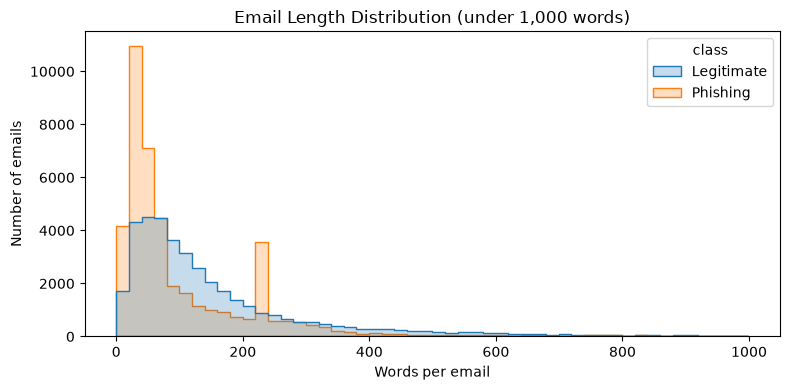

Median words per email:
class
Legitimate    106.0
Phishing       55.0
Name: word_count, dtype: float64


In [5]:
import seaborn as sns

df["class"] = df["label"].map({0: "Legitimate", 1: "Phishing"})
short = df[df["word_count"] < 1000]

plt.figure(figsize=(8, 4))
sns.histplot(data=short, x="word_count", hue="class", bins=50, element="step")
plt.title("Email Length Distribution (under 1,000 words)")
plt.xlabel("Words per email")
plt.ylabel("Number of emails")
plt.tight_layout()
plt.savefig("figures/email_length.png", dpi=150)
plt.show()

print("Median words per email:")
print(df.groupby("class")["word_count"].median())


### 3.3 Most frequent words
The 15 most common words in each class (after removing English stop words) give a first look at the vocabulary each class uses.

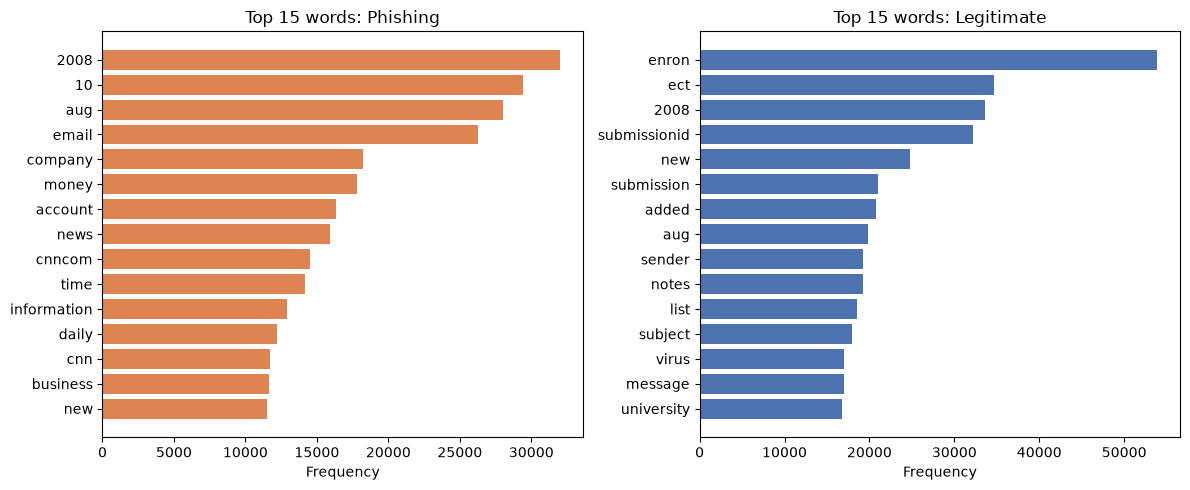

In [6]:
from sklearn.feature_extraction.text import CountVectorizer
import numpy as np

def top_words(texts, n=15):
    cv = CountVectorizer(stop_words="english", max_features=5000)
    X = cv.fit_transform(texts)
    freqs = np.asarray(X.sum(axis=0)).ravel()
    return pd.Series(freqs, index=cv.get_feature_names_out()).nlargest(n)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (lbl, name, colour) in zip(axes, [(1, "Phishing", "#DD8452"), (0, "Legitimate", "#4C72B0")]):
    tw = top_words(df[df["label"] == lbl]["text_combined"].astype(str))
    ax.barh(tw.index[::-1], tw.values[::-1], color=colour)
    ax.set_title(f"Top 15 words: {name}")
    ax.set_xlabel("Frequency")
plt.tight_layout()
plt.savefig("figures/top_words.png", dpi=150)
plt.show()

## 4. Data pre-processing
### 4.1 Remove duplicates and empty emails
Duplicate emails could appear in both the training and test sets and inflate the results, so they are removed along with the empty email.

In [7]:
before = len(df)
df = df.drop_duplicates(subset="text_combined")
df = df[df["word_count"] > 0].reset_index(drop=True)

print(f"Removed {before - len(df)} rows")
print(f"Emails remaining: {len(df)}")
print(df["label"].value_counts())

Removed 409 rows
Emails remaining: 82077
label
1    42844
0    39233
Name: count, dtype: int64


### 4.2 Text cleaning (text mining)
Each email is lowercased, links and email addresses are replaced with placeholder tokens (`urltoken`, `emailtoken`), and numbers and symbols are removed. The text is then tokenised, stop words are removed, and words are lemmatised with NLTK. Very long emails are capped at 1,000 words to limit the effect of outliers.

In [8]:
import re
import nltk
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()
MAX_WORDS = 1000   # cap very long emails (some have 100,000+ words)

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " urltoken ", text)   # mark links
    text = re.sub(r"\S+@\S+", " emailtoken ", text)          # mark email addresses
    text = re.sub(r"[^a-z\s]", " ", text)                    # remove numbers and symbols
    tokens = text.split()[:MAX_WORDS]                         # tokenisation
    tokens = [lemmatizer.lemmatize(t) for t in tokens
              if t not in stop_words and len(t) > 2]          # stop words + lemmatisation
    return " ".join(tokens)

# Test it on a fake phishing email
print(clean_text("URGENT!! Verify your accounts now at http://bank-login.com or email support@fake.com in 2008"))

urgent verify account urltoken email emailtoken


### 4.3 Apply cleaning to all emails
The cleaned emails are saved to `cleaned_emails.csv`. Emails that become empty after cleaning are removed. Three before/after examples are printed.

In [9]:
import time
start = time.time()

df["clean_text"] = df["text_combined"].apply(clean_text)
df = df[df["clean_text"].str.len() > 0].reset_index(drop=True)

df[["clean_text", "label"]].to_csv("cleaned_emails.csv", index=False)

print(f"Done in {time.time() - start:.0f} seconds")
print("Cleaned emails saved:", len(df))

# Before vs after examples (screenshot these for your report)
for i in range(3):
    print("\nBEFORE:", df["text_combined"][i][:150])
    print("AFTER: ", df["clean_text"][i][:150])

Done in 30 seconds
Cleaned emails saved: 82075

BEFORE: hpl nom may 25 2001 see attached file hplno 525 xls hplno 525 xls
AFTER:  hpl nom may see attached file hplno xl hplno xl

BEFORE: nom actual vols 24 th forwarded sabrae zajac hou ect 05 30 2001 12 07 pm enron capital trade resources corp eileen ponton 05 29 2001 08 37 davilal txu
AFTER:  nom actual vols forwarded sabrae zajac hou ect enron capital trade resource corp eileen ponton davilal txu com cstonel txu com mjones txu com hpl sche

BEFORE: enron actuals march 30 april 1 201 estimated actuals march 30 2001 flow march 31 2001 flow april 1 2001 teco tap 35 000 receive actuals duke forward
AFTER:  enron actuals march april estimated actuals march flow march flow april teco tap receive actuals duke forward


## 5. Train/test split
The data is split 70% training and 30% testing. Stratification keeps the same phishing share in both sets. The test set is only used for final evaluation.

In [10]:
from sklearn.model_selection import train_test_split

X = df["clean_text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print("Training emails:", len(X_train))
print("Testing emails: ", len(X_test))
print("\nPhishing share in train:", round(y_train.mean() * 100, 1), "%")
print("Phishing share in test: ", round(y_test.mean() * 100, 1), "%")

Training emails: 57452
Testing emails:  24623

Phishing share in train: 52.2 %
Phishing share in test:  52.2 %


## 6. Feature extraction and selection
**TF-IDF** turns each email into numbers that show how important each word and two-word phrase (n-gram) is. It is fitted on the training data only to avoid data leakage. **Chi-square** then keeps the 5,000 features that best separate phishing from legitimate emails.

Note: some top features (for example `enron`, `cnn`, `python`) reveal which source collection an email came from rather than whether it is phishing. This source bias is a known limitation of the dataset.

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2

# 1. TF-IDF with single words + two-word phrases (n-grams)
tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=50000, min_df=2, sublinear_tf=True)
X_train_tfidf = tfidf.fit_transform(X_train)   # learn vocabulary from TRAIN only
X_test_tfidf = tfidf.transform(X_test)         # apply the same vocabulary to TEST

# 2. Chi-square: keep the 5,000 most useful features
selector = SelectKBest(chi2, k=5000)
X_train_sel = selector.fit_transform(X_train_tfidf, y_train)
X_test_sel = selector.transform(X_test_tfidf)

print("TF-IDF features:  ", X_train_tfidf.shape[1])
print("After chi-square: ", X_train_sel.shape[1])

# 3. Show the 20 features that best separate phishing from legitimate
scores = pd.Series(selector.scores_, index=tfidf.get_feature_names_out())
print("\nTop 20 features by chi-square score:")
print(scores.nlargest(20).round(1))

TF-IDF features:   50000
After chi-square:  5000

Top 20 features by chi-square score:
enron            501.9
wrote            422.3
replica          363.7
watch            352.2
cnncom           311.6
cnn              302.1
ect              287.0
cable news       255.0
news network     253.2
python           251.3
cable            241.2
replica watch    239.1
file             235.1
hou ect          231.3
hou              228.6
list             217.2
daily top        215.7
ect ect          214.2
thanks           210.8
subject          207.3
dtype: float64


## 7. Baseline models
Four algorithms are trained with default settings: Logistic Regression, Linear SVM, Naive Bayes and Random Forest. They are evaluated on the test set with accuracy, precision, recall and F1.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import time

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM (Linear)": LinearSVC(),
    "Naive Bayes": MultinomialNB(),
    "Random Forest": RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42),
}

results = []
for name, model in models.items():
    start = time.time()
    model.fit(X_train_sel, y_train)      # learn from training data
    pred = model.predict(X_test_sel)     # predict on unseen test data
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "Train time (s)": round(time.time() - start, 1),
    })
    print(f"{name} done")

results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df

Logistic Regression done
SVM (Linear) done
Naive Bayes done
Random Forest done


,Accuracy,Precision,Recall,F1,Train time (s)
Model,,,,,
Logistic Regression,0.9768,0.9704,0.9856,0.9780,1.2
SVM (Linear),0.9833,0.9788,0.9895,0.9841,0.8
Naive Bayes,0.9421,0.9884,0.8997,0.9420,0.1
Random Forest,0.9820,0.9818,0.9838,0.9828,14.0


## 8. Hyperparameter tuning
Grid search with cross-validation (5 folds, or 3 for the slower Random Forest) finds the best settings for each model using only the training data. The cross-validation folds act as the validation set. The tuned models are then tested on the unseen test set.

In [13]:
from sklearn.model_selection import GridSearchCV

param_grids = {
    "Logistic Regression": (LogisticRegression(max_iter=2000), {"C": [0.1, 1, 10, 100]}),
    "SVM (Linear)":        (LinearSVC(max_iter=5000),          {"C": [0.01, 0.1, 1, 10]}),
    "Naive Bayes":         (MultinomialNB(),                   {"alpha": [0.01, 0.1, 0.5, 1.0]}),
    "Random Forest":       (RandomForestClassifier(n_jobs=-1, random_state=42),
                            {"n_estimators": [100, 200], "max_depth": [None, 50]}),
}

tuned_models = {}
tuned_results = []

for name, (model, grid) in param_grids.items():
    start = time.time()
    cv = 3 if name == "Random Forest" else 5          # fewer folds for the slow model
    search = GridSearchCV(model, grid, cv=cv, scoring="f1", n_jobs=-1)
    search.fit(X_train_sel, y_train)
    best = search.best_estimator_
    tuned_models[name] = best
    pred = best.predict(X_test_sel)
    tuned_results.append({
        "Model": name,
        "Best settings": str(search.best_params_),
        "CV F1": round(search.best_score_, 4),
        "Test Accuracy": round(accuracy_score(y_test, pred), 4),
        "Test Precision": round(precision_score(y_test, pred), 4),
        "Test Recall": round(recall_score(y_test, pred), 4),
        "Test F1": round(f1_score(y_test, pred), 4),
    })
    print(f"{name} tuned in {time.time() - start:.0f}s -> {search.best_params_}")

tuned_df = pd.DataFrame(tuned_results).set_index("Model")
tuned_df

Logistic Regression tuned in 4s -> {'C': 100}
SVM (Linear) tuned in 4s -> {'C': 1}
Naive Bayes tuned in 1s -> {'alpha': 0.01}
Random Forest tuned in 125s -> {'max_depth': None, 'n_estimators': 200}


,Best settings,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1
Model,,,,,,
Logistic Regression,{'C': 100},0.9817,0.9817,0.9796,0.9855,0.9825
SVM (Linear),{'C': 1},0.9842,0.9833,0.9788,0.9895,0.9841
Naive Bayes,{'alpha': 0.01},0.9504,0.9474,0.9886,0.9098,0.9476
Random Forest,"{'max_depth': None, 'n_estimators': 200}",0.9830,0.9831,0.9816,0.9861,0.9839


## 9. Evaluation
### 9.1 Confusion matrices
Show how many emails each tuned model classified correctly and incorrectly. False negatives (phishing marked as legitimate) are the most dangerous errors.

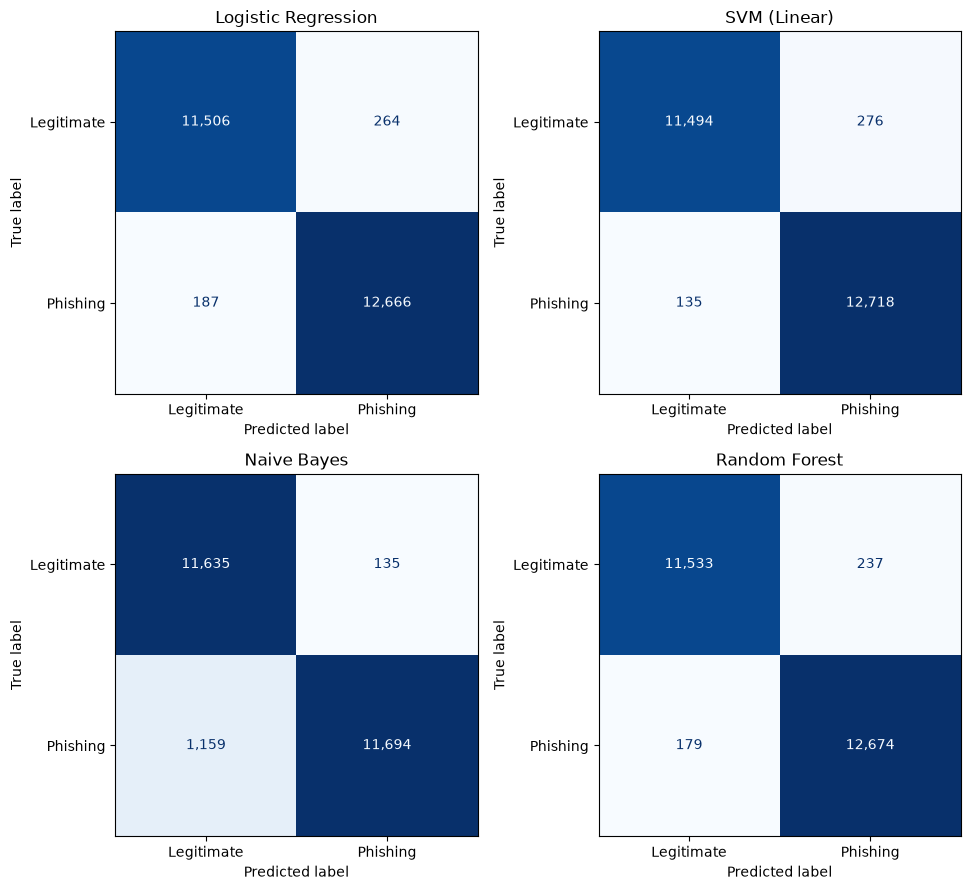

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for ax, (name, model) in zip(axes.ravel(), tuned_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test_sel, y_test,
        display_labels=["Legitimate", "Phishing"],
        cmap="Blues", ax=ax, colorbar=False, values_format=","
    )
    ax.set_title(name)
plt.tight_layout()
plt.savefig("figures/confusion_matrices.png", dpi=150)
plt.show()

### 9.2 ROC curves and ROC-AUC
ROC curves show the trade-off between catching phishing and raising false alarms at every threshold. ROC-AUC summarises this as one number (1.0 is perfect).

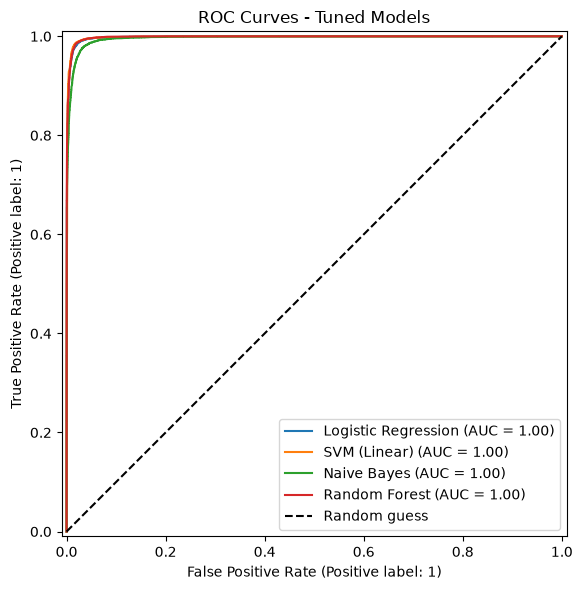

ROC-AUC scores:
  Logistic Regression: 0.9978
  SVM (Linear): 0.9979
  Naive Bayes: 0.9958
  Random Forest: 0.9982


In [15]:
from sklearn.metrics import RocCurveDisplay, roc_auc_score

fig, ax = plt.subplots(figsize=(7, 6))
auc_scores = {}
for name, model in tuned_models.items():
    RocCurveDisplay.from_estimator(model, X_test_sel, y_test, name=name, ax=ax)
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_test_sel)[:, 1]
    else:
        scores = model.decision_function(X_test_sel)
    auc_scores[name] = roc_auc_score(y_test, scores)

ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.set_title("ROC Curves - Tuned Models")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("figures/roc_curves.png", dpi=150)
plt.show()

print("ROC-AUC scores:")
for name, auc in auc_scores.items():
    print(f"  {name}: {auc:.4f}")

## 10. Best model selection and explainability
Logistic Regression is chosen as the main model. Its F1 score is within 0.2% of the best model, and it gives a probability and a weight for every word, so each decision can be explained. The chart shows the words with the strongest weights towards each class.

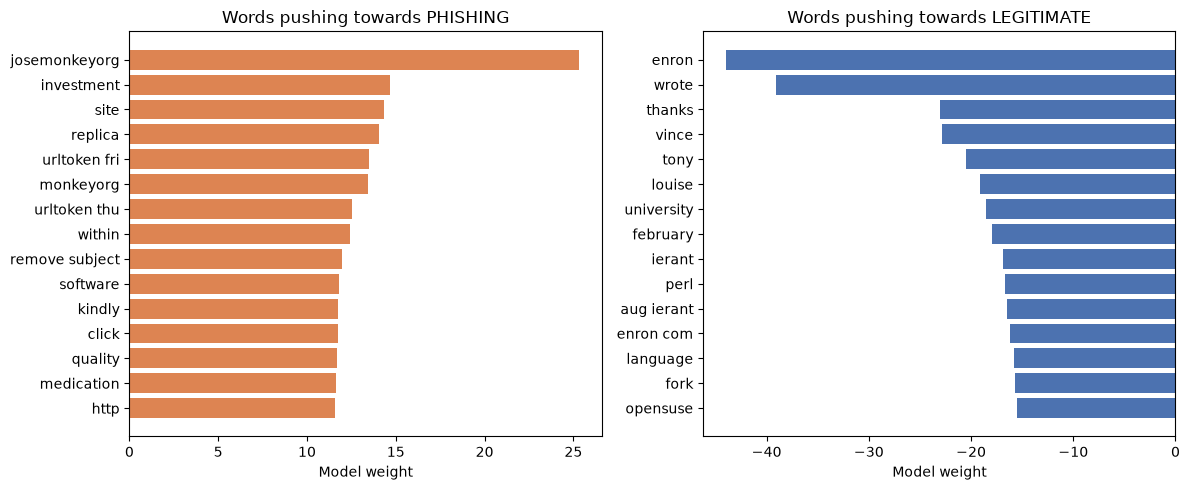

In [16]:

lr = tuned_models["Logistic Regression"]
feature_names = tfidf.get_feature_names_out()[selector.get_support()]
coefs = pd.Series(lr.coef_[0], index=feature_names)

top_phish = coefs.nlargest(15)
top_legit = coefs.nsmallest(15)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].barh(top_phish.index[::-1], top_phish.values[::-1], color="#DD8452")
axes[0].set_title("Words pushing towards PHISHING")
axes[0].set_xlabel("Model weight")
axes[1].barh(top_legit.index[::-1], top_legit.values[::-1], color="#4C72B0")
axes[1].set_title("Words pushing towards LEGITIMATE")
axes[1].set_xlabel("Model weight")
plt.tight_layout()
plt.savefig("figures/lr_explainability.png", dpi=150)
plt.show()

### 10.1 Explaining individual predictions
For a new email, each word's contribution is its TF-IDF value multiplied by the model weight. Two example emails (one phishing, one legitimate) show which words drove each decision.

In [17]:
def explain_email(raw_text, top_n=8):
    cleaned = clean_text(raw_text)
    vec = selector.transform(tfidf.transform([cleaned]))
    prob = lr.predict_proba(vec)[0, 1]
    contrib = pd.Series(vec.toarray()[0] * lr.coef_[0], index=feature_names)
    contrib = contrib[contrib != 0].sort_values(key=abs, ascending=False).head(top_n)

    print(f"Phishing probability: {prob:.1%}  ->  {'PHISHING' if prob >= 0.5 else 'LEGITIMATE'}")
    print("Top words behind this decision (+ = phishing, - = legitimate):")
    print(contrib.round(3).to_string())
    print("-" * 60)

explain_email("Dear customer, your account has been suspended. Verify your password immediately at http://secure-login.com to avoid closure.")
explain_email("Hi team, attached are the notes from today's meeting. Let me know if anything is missing. Thanks, John")

Phishing probability: 100.0%  ->  PHISHING
Top words behind this decision (+ = phishing, - = legitimate):
verify           2.670
dear customer    2.619
immediately      2.262
account          1.849
suspended        1.526
dear             1.267
urltoken        -0.654
customer        -0.398
------------------------------------------------------------
Phishing probability: 0.0%  ->  LEGITIMATE
Top words behind this decision (+ = phishing, - = legitimate):
thanks     -4.020
john       -2.576
meeting    -2.218
let know   -1.600
attached   -1.197
note       -0.927
team       -0.866
let         0.642
------------------------------------------------------------


## 11. Save the model
The TF-IDF vectoriser, chi-square selector and Logistic Regression model are saved to the `model/` folder so the Flask web app (`app.py`) can use them. The results table is saved to `figures/tuned_results.csv`.

In [18]:
import joblib

os.makedirs("model", exist_ok=True)

tfidf.stop_words_ = None   # removes a large unused attribute -> much smaller file
joblib.dump(tfidf, "model/tfidf.pkl")
joblib.dump(selector, "model/selector.pkl")
joblib.dump(lr, "model/logistic_regression.pkl")

tuned_df.to_csv("figures/tuned_results.csv")   # results table for your report

for f in os.listdir("model"):
    size_mb = os.path.getsize(f"model/{f}") / 1_000_000
    print(f"{f}: {size_mb:.1f} MB")

logistic_regression.pkl: 0.0 MB
selector.pkl: 0.8 MB
tfidf.pkl: 2.0 MB
